# MolBERT embeddings

- This notebook generates embeddings across several datasets using the **MolBERT** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [1]:
import pandas as pd
import rdkit 
from rdkit import Chem
import numpy as np
from rdkit import DataStructs
import sklearn
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm
from itertools import islice
import numpy as np

from rdkit import RDLogger
RDLogger.DisableLog("rdApp.warning")


import math
from collections.abc import Sized
from tqdm.auto import tqdm
from molbert.utils.featurizer.molbert_featurizer import MolBertFeaturizer

/home/blake/miniconda3/envs/molbert/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## File paths

Edit the following paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''
CKPT_PATH    = ''

# Model set-up

In [3]:
# Load featurizer
featurizer = MolBertFeaturizer(CKPT_PATH)

In [ ]:
def chunked(iterable, batch_size):
    """ Yield lists of size batch_size from any iterable."""
    iterator = iter(iterable)
    while True:
        batch = list(islice(iterator, batch_size))
        if not batch:
            break
        yield batch


def molbert_transform_batched(featurizer, smiles, batch_size=256):
    """
    Batched MolBERT featurization.

    Parameters
    ----------
    featurizer : object
        MolBERT featurizer with .transform(smiles_batch).
    smiles : list[str] or iterable[str]
        SMILES strings.
    batch_size : int
        Number of molecules per batch.

    Returns
    -------
    embeddings : np.ndarray
    masks : np.ndarray
    """
    all_embeddings = []
    all_masks = []

    for smiles_batch in chunked(smiles, batch_size):
        batch_embeddings, batch_masks = featurizer.transform(smiles_batch)

        all_embeddings.append(batch_embeddings)
        all_masks.append(batch_masks)

    embeddings = np.concatenate(all_embeddings, axis=0)
    masks      = np.concatenate(all_masks, axis=0)

    return embeddings, masks



def molbert_transform_batched_tdqm(featurizer, smiles, batch_size=256):
    """
    Batched MolBERT featurization.

    Parameters
    ----------
    featurizer : object
        MolBERT featurizer with .transform(smiles_batch).
    smiles : iterable[str]
        SMILES strings.
    batch_size : int, default=256
        Number of molecules per batch.

    Returns
    -------
    embeddings : np.ndarray
        MolBERT embeddings in the same order as the input SMILES.
    masks : np.ndarray
        Boolean validity mask for the input SMILES.
    """
    if batch_size <= 0:
        raise ValueError("batch_size must be greater than zero.")

    # Gives tqdm a known total for lists, arrays, Series, etc.
    total_batches = (
        math.ceil(len(smiles) / batch_size)
        if isinstance(smiles, Sized)
        else None
    )

    all_embeddings = []
    all_masks = []

    batches = chunked(smiles, batch_size)

    for smiles_batch in tqdm(
        batches,
        total=total_batches,
        desc="MolBERT featurization",
        unit="batch",
    ):
        batch_embeddings, batch_masks = featurizer.transform(smiles_batch)

        all_embeddings.append(batch_embeddings)
        all_masks.append(batch_masks)

    embeddings = np.concatenate(all_embeddings, axis=0)
    masks      = np.concatenate(all_masks, axis=0)

    return embeddings, masks

## MCES

In [ ]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [9]:
mols              = [Chem.MolFromSmiles(s) for s in smiles]
smiles            = [Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) for s in smiles]
embeddings, masks = molbert_transform_batched_tdqm(featurizer, smiles, batch_size=1024)

MolBERT featurization: 100%|██████████| 62/62 [1:28:38<00:00, 85.78s/batch]


In [ ]:
np.save('MCES/MolBERT valid.npy', masks)
np.save('MCES/MolBERT MCES embeddings.npy', embeddings)

In [ ]:
X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/MolBERT MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [02:54<00:00,  2.72s/it]


Expected length: 2012094766
Written length: 2012094766


In [17]:
n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/MolBERT MCES pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:07<00:00, 8253.31it/s] 


Expected: 2012094766
Written: 2012094766


## MCES figure examples

Cosine similarity: [[0.9473618]]


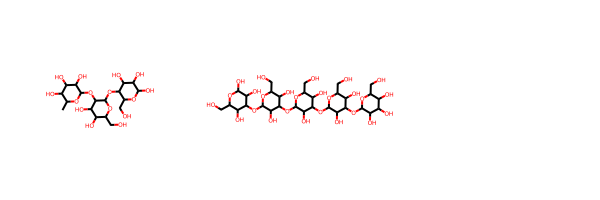

In [5]:
close_pair_a = "CC1C(C(C(C(O1)OC2C(C(C(OC2OC3C(OC(C(C3O)O)O)CO)CO)O)O)O)O)O"
close_pair_b = "C(C1C(C(C(C(O1)O)O)OC2C(C(C(C(O2)CO)O)OC3C(C(C(C(O3)CO)O)OC4C(C(C(C(O4)CO)O)OC5C(C(C(C(O5)CO)O)O)O)O)O)O)O)O"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings, _ = featurizer.transform([close_pair_a, close_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

Cosine similarity: [[0.4946786]]


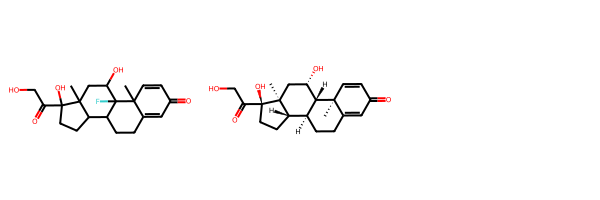

In [ ]:
distant_pair_a = "CC12CC(C3(C(C1CCC2(C(=O)CO)O)CCC4=CC(=O)C=CC43C)F)O"
distant_pair_b = "C[C@]12C[C@@H]([C@H]3[C@H]([C@@H]1CC[C@@]2(C(=O)CO)O)CCC4=CC(=O)C=C[C@]34C)O"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings, _ = featurizer.transform([distant_pair_a, distant_pair_b])
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

## Biogen

In [ ]:
biogen  = pd.read_csv(BIOGEN_PATH)
smiles  = biogen['SMILES'].tolist()
mols    = [Chem.MolFromSmiles(s) for s in smiles]
smiles  = [Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) for s in smiles]

In [7]:
embeddings, masks = featurizer.transform(smiles)
embeddings        = np.asarray(embeddings)
np.save('Biogen/MolBERT Biogen embeddings.npy', embeddings)
np.save('Biogen/MolBERT Biogen invalid.npy', ~masks)

## ZINC

In [ ]:
# ZINC file contains randomly sampled molecules. 
data    = pd.read_csv(ZINC30K_PATH)[:30000]
smiles  = data['SMILES'].tolist()
mols    = [Chem.MolFromSmiles(s) for s in smiles]
smiles  = [Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True) for s in smiles]

In [9]:
embeddings, masks = molbert_transform_batched_tdqm(featurizer, smiles, batch_size=1024)

MolBERT featurization: 100%|██████████| 30/30 [30:31<00:00, 61.06s/batch]


In [ ]:
# All valid
masks.sum()

30000

In [ ]:
np.save('ZINC/MolBERT ZINC30K embeddings.npy', embeddings)